# 02 · Training: Multi-Horizon Fire Risk Model

**Purpose:** split the labelled data, build the preprocessing + model pipeline, compare candidate models with 5-fold cross-validation, tune the best one, and save it.

**Inputs:** `data/processed/train_clean.csv` (from notebook 01).

**Outputs:**
- `data/test/test_set.csv`: held-out 15% test split, **not used again until notebook 03**
- `data/processed/dev_set.csv`: the 85% development split
- `models/fire_risk_model.joblib`: the final fitted pipeline bundle
- `reports/figures/02_*.png` and `reports/cv_results.csv`

**Framing:** one binary classifier per horizon h ∈ {12, 24, 48, 72} h, with target `hit_h = event==1 and time_to_hit ≤ h`. Risk % = `predict_proba × 100`, made non-decreasing across horizons.

## Setup

In [1]:
import os, sys, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, sklearn
from sklearn.model_selection import StratifiedKFold, train_test_split, cross_validate, GridSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
os.environ["PYTHONPATH"] = str(ROOT) + os.pathsep + os.environ.get("PYTHONPATH", "")  # so parallel workers can import src

from src.data import feature_columns, horizon_labels, HORIZONS, ID_COL, TIME_COL, EVENT_COL, TARGET_COLS
from src.model import MultiHorizonRiskModel, make_pipeline, SCORING, horizon_scores

DATA_DIR = ROOT / "data"
PROC_DIR, TEST_DIR, MODEL_DIR = DATA_DIR / "processed", DATA_DIR / "test", ROOT / "models"
FIG_DIR, REPORT_DIR = ROOT / "reports" / "figures", ROOT / "reports"
for d in (TEST_DIR, MODEL_DIR, FIG_DIR): d.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
def save(fig, name): fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=130)
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.1


## 1. Train / test split (85 / 15, stratified)
We agreed on **85% development / 15% test** with 5-fold CV on the development part instead of a separate 15% validation set: with 221 rows, a 33-row validation set would make model selection close to random.

We stratify on a 3-level key (*never hit*, *hit after 12 h*, *hit within 12 h*), so every split contains both early and late hits.

In [2]:
df = pd.read_csv(PROC_DIR / "train_clean.csv")
FEATURES = feature_columns(df.drop(columns=[c for c in df.columns if c.startswith("hit_")]))
strata = df[EVENT_COL] + df["hit_12h"]          # 0 = never, 1 = late hit, 2 = early hit

dev, test = train_test_split(df, test_size=0.15, stratify=strata, random_state=RANDOM_STATE)
dev, test = dev.reset_index(drop=True), test.reset_index(drop=True)

raw_cols = [ID_COL] + FEATURES + TARGET_COLS
test[raw_cols].to_csv(TEST_DIR / "test_set.csv", index=False)   # untouched until notebook 03
dev[raw_cols].to_csv(PROC_DIR / "dev_set.csv", index=False)

balance = pd.DataFrame({name: part[[f"hit_{h}h" for h in HORIZONS]].mean().mul(100).round(1)
                        for name, part in [("dev", dev), ("test", test)]})
balance.loc["rows"] = [len(dev), len(test)]
print(f"{len(FEATURES)} features"); balance

34 features


,dev,test
hit_12h,21.9,23.5
hit_24h,28.3,29.4
hit_48h,29.4,32.4
hit_72h,31.0,32.4
rows,187.0,34.0


Both splits keep about the same positive rate at every horizon. The test file is now on disk and is **not read again in this notebook**.

In [3]:
X_dev = dev[FEATURES]
y_dev = dev[TARGET_COLS].to_numpy()          # [time_to_hit_hours, event]
strata_dev = (dev[EVENT_COL] + dev["hit_12h"]).to_numpy()
cv_splits = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(X_dev, strata_dev))
print("fold sizes (validation):", [len(v) for _, v in cv_splits])

fold sizes (validation): [38, 38, 37, 37, 37]


## 2. Pipeline
Each horizon model is the same sklearn `Pipeline`:

1. `FeatureEngineer`: adds `log_dist_min`, `dist_minus_radius_km`, `within_10km`, `eta_hours`, `has_growth` and sin/cos encodings of hour and month (see `src/features.py`)
2. `ColumnTransformer`: numeric → `SimpleImputer(median)` → `StandardScaler`. Categorical → `SimpleImputer(most_frequent)` → `OneHotEncoder(handle_unknown="ignore")` (the categorical branch is empty for this data).
3. the classifier

`MultiHorizonRiskModel` clones the pipeline for each of the 4 horizons and enforces P(12h) ≤ P(24h) ≤ P(48h) ≤ P(72h). Every preprocessing step is fitted inside the CV folds, so nothing leaks from the validation folds.

In [4]:
example = make_pipeline(LogisticRegression(max_iter=5000))
for name, step in example.steps:
    print(f"{name:>9}: {type(step).__name__}")
for name, trans, _ in example.named_steps["prep"].transformers:
    print(f"{'':>11}{name}: " + " -> ".join(f"{type(s).__name__}({s.get_params().get('strategy', '')})".replace("()", "") for _, s in trans.steps))

 features: FeatureEngineer
     prep: ColumnTransformer
      clf: LogisticRegression
           num: SimpleImputer(median) -> StandardScaler
           cat: SimpleImputer(most_frequent) -> OneHotEncoder


## 3. Model comparison (5-fold CV)
**Metrics**
- **Mean Brier score** (primary, lower is better): the mean squared error of the predicted probabilities. It rewards both ranking and calibration, which matters because we report the risk **as a percentage**.
- **Mean ROC-AUC** across horizons: ranking quality.
- **C-index**: ranking of fires by how soon they hit (a standard survival metric), using the mean of the 4 probabilities.

`DummyClassifier(prior)` is included as a no-skill baseline.

In [5]:
candidates = {
    "Baseline (prior)": DummyClassifier(strategy="prior"),
    "LogisticRegression": LogisticRegression(max_iter=5000),
    "RandomForest": RandomForestClassifier(n_estimators=500, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=1),
    "GradientBoosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}
per_h = {f"auc_{h}h": (lambda h: lambda m, X, y: horizon_scores(m, X, y)[f"auc_{h}h"])(h) for h in HORIZONS}
per_h |= {f"brier_{h}h": (lambda h: lambda m, X, y: -horizon_scores(m, X, y)[f"brier_{h}h"])(h) for h in HORIZONS}
scoring = SCORING | per_h

rows = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for name, clf in candidates.items():
        res = cross_validate(MultiHorizonRiskModel(make_pipeline(clf)), X_dev, y_dev, cv=cv_splits, scoring=scoring, n_jobs=-1)
        row = {"model": name}
        for k in scoring:
            v = res[f"test_{k}"] * (-1 if k.startswith(("neg_", "brier_")) else 1)
            key = k.replace("neg_", "")
            row[f"{key}_mean"], row[f"{key}_std"] = v.mean(), v.std()
        rows.append(row)
cv_table = pd.DataFrame(rows).set_index("model")
cv_table.to_csv(REPORT_DIR / "cv_results.csv")
show = ["mean_brier_mean", "mean_brier_std", "mean_auc_mean", "mean_auc_std", "c_index_mean", "c_index_std"] + [f"auc_{h}h_mean" for h in HORIZONS]
cv_table[show].sort_values("mean_brier_mean").round(4)

,mean_brier_mean,mean_brier_std,mean_auc_mean,mean_auc_std,c_index_mean,c_index_std,auc_12h_mean,auc_24h_mean,auc_48h_mean,auc_72h_mean
model,,,,,,,,,,
RandomForest,0.0264,0.0060,0.9907,0.0063,0.9516,0.0182,0.9717,0.9918,0.9993,1.0000
GradientBoosting,0.0312,0.0090,0.9878,0.0076,0.9434,0.0185,0.9649,0.9904,0.9960,1.0000
LogisticRegression,0.0740,0.0339,0.9581,0.0367,0.9109,0.0430,0.9355,0.9550,0.9672,0.9746
Baseline (prior),0.1990,0.0031,0.5000,0.0000,0.5000,0.0000,0.5000,0.5000,0.5000,0.5000


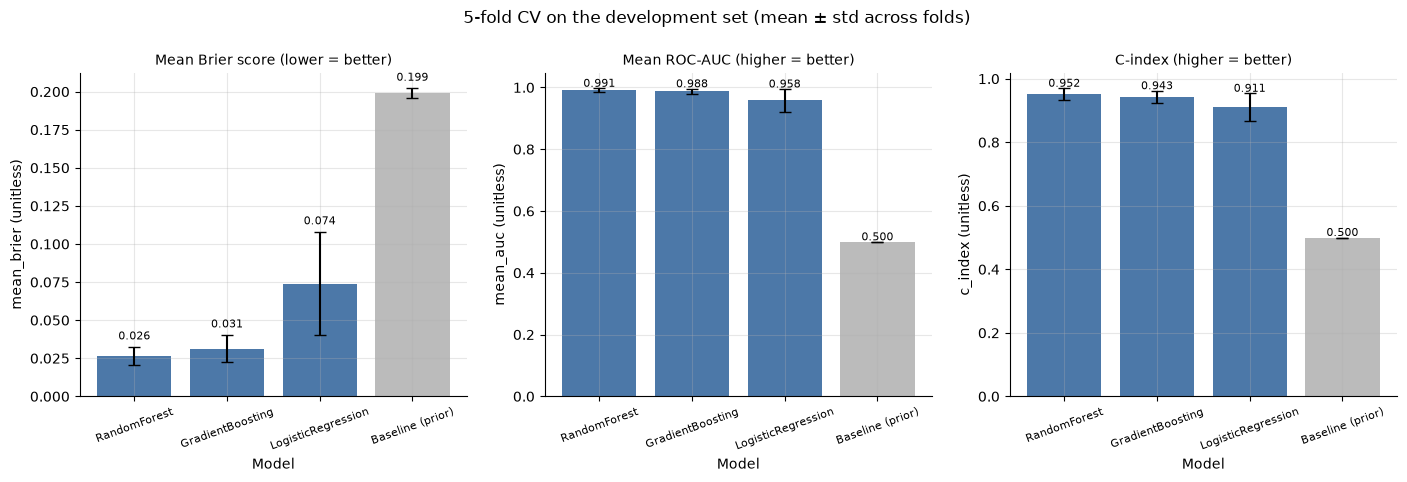

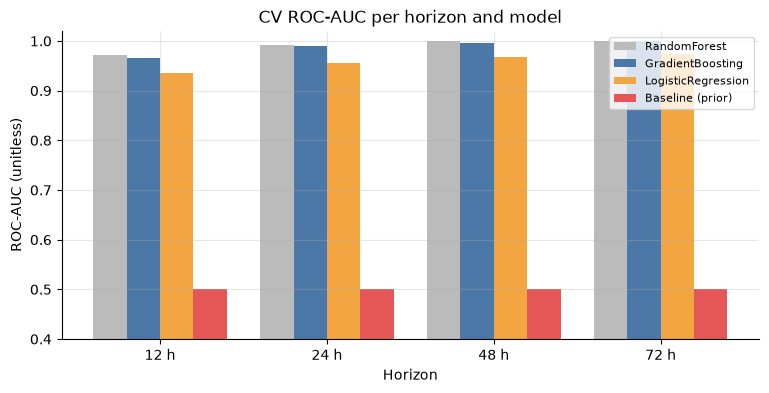

In [6]:
order = cv_table.sort_values("mean_brier_mean").index
colors = ["#BBBBBB" if "Baseline" in m else "#4C78A8" for m in order]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, (metric, label) in zip(axes, [("mean_brier", "Mean Brier score (lower = better)"),
                                       ("mean_auc", "Mean ROC-AUC (higher = better)"),
                                       ("c_index", "C-index (higher = better)")]):
    m, s = cv_table.loc[order, f"{metric}_mean"], cv_table.loc[order, f"{metric}_std"]
    ax.bar(range(len(order)), m, yerr=s, capsize=4, color=colors)
    for i, v in enumerate(m): ax.text(i, v + s.iloc[i] + 0.005, f"{v:.3f}", ha="center", fontsize=8)
    ax.set_xticks(range(len(order)), order, rotation=20, fontsize=8)
    ax.set_title(label, fontsize=10); ax.set_ylabel(metric + " (unitless)"); ax.set_xlabel("Model")
fig.suptitle("5-fold CV on the development set (mean ± std across folds)", y=1.03)
save(fig, "02_cv_model_comparison"); plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
w = 0.2
for i, name in enumerate(order):
    ax.bar(np.arange(len(HORIZONS)) + (i - 1.5) * w, [cv_table.loc[name, f"auc_{h}h_mean"] for h in HORIZONS], width=w, label=name, color=["#BBBBBB", "#4C78A8", "#F2A541", "#E45756"][i])
ax.set_xticks(range(len(HORIZONS)), [f"{h} h" for h in HORIZONS]); ax.set_ylim(0.4, 1.02)
ax.set_xlabel("Horizon"); ax.set_ylabel("ROC-AUC (unitless)"); ax.set_title("CV ROC-AUC per horizon and model"); ax.legend(fontsize=8)
save(fig, "02_cv_auc_per_horizon"); plt.show()

## 4. Hyper-parameter tuning (`GridSearchCV`)
We tune the model family with the best (lowest) CV mean Brier score, using the same 5 folds and refitting on mean Brier. The grids are kept small because 187 rows cannot support a fine search without overfitting the CV.

In [7]:
best_family = cv_table.drop(index="Baseline (prior)")["mean_brier_mean"].idxmin()
grids = {
    "LogisticRegression": {"estimator__clf__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]},
    "RandomForest": {"estimator__clf__n_estimators": [500],
                     "estimator__clf__max_depth": [None, 4, 8],
                     "estimator__clf__min_samples_leaf": [1, 3, 5, 10],
                     "estimator__clf__max_features": ["sqrt", 0.5]},
    "GradientBoosting": {"estimator__clf__n_estimators": [50, 100, 200],
                         "estimator__clf__learning_rate": [0.03, 0.1],
                         "estimator__clf__max_depth": [2, 3],
                         "estimator__clf__subsample": [0.7, 1.0],
                         "estimator__clf__min_samples_leaf": [3, 10]},
}
print("Tuning:", best_family, "| grid size:", int(np.prod([len(v) for v in grids[best_family].values()])))
search = GridSearchCV(MultiHorizonRiskModel(make_pipeline(candidates[best_family])), grids[best_family],
                      scoring=SCORING, refit="neg_mean_brier", cv=cv_splits, n_jobs=-1)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    search.fit(X_dev, y_dev)

res = pd.DataFrame(search.cv_results_)
res["mean_brier"] = -res["mean_test_neg_mean_brier"]
top = res.sort_values("mean_brier")[["params", "mean_brier", "std_test_neg_mean_brier", "mean_test_mean_auc", "mean_test_c_index"]].head(10)
top["params"] = top["params"].apply(lambda p: {k.replace("estimator__clf__", ""): v for k, v in p.items()})
print("best params:", top.iloc[0]["params"])
top.round(4)

Tuning: RandomForest | grid size: 24


best params: {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 3, 'n_estimators': 500}


,params,mean_brier,std_test_neg_mean_brier,mean_test_mean_auc,mean_test_c_index
5,"{'max_depth': None, 'max_features': 0.5, 'min_...",0.0213,0.0054,0.9925,0.9521
21,"{'max_depth': 8, 'max_features': 0.5, 'min_sam...",0.0213,0.0054,0.9925,0.9521
13,"{'max_depth': 4, 'max_features': 0.5, 'min_sam...",0.0214,0.0053,0.9923,0.9527
6,"{'max_depth': None, 'max_features': 0.5, 'min_...",0.0215,0.0059,0.9928,0.9538
22,"{'max_depth': 8, 'max_features': 0.5, 'min_sam...",0.0215,0.0059,0.9928,0.9538
14,"{'max_depth': 4, 'max_features': 0.5, 'min_sam...",0.0216,0.0059,0.9928,0.9538
20,"{'max_depth': 8, 'max_features': 0.5, 'min_sam...",0.0222,0.0049,0.9911,0.9483
4,"{'max_depth': None, 'max_features': 0.5, 'min_...",0.0222,0.0049,0.9911,0.9483
12,"{'max_depth': 4, 'max_features': 0.5, 'min_sam...",0.0225,0.0047,0.9910,0.9504
23,"{'max_depth': 8, 'max_features': 0.5, 'min_sam...",0.0235,0.0066,0.9922,0.9513


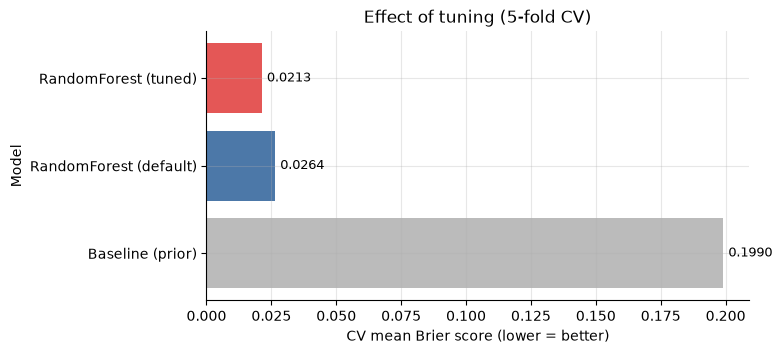

,mean_brier,mean_auc,c_index
Baseline (prior),0.1990,0.5000,0.5000
RandomForest (default),0.0264,0.9907,0.9516
RandomForest (tuned),0.0213,0.9925,0.9521


In [8]:
default_brier = cv_table.loc[best_family, "mean_brier_mean"]
tuned_brier = -search.best_score_
tuned_row = res.loc[search.best_index_]
compare = pd.DataFrame({
    "mean_brier": [cv_table.loc["Baseline (prior)", "mean_brier_mean"], default_brier, tuned_brier],
    "mean_auc": [cv_table.loc["Baseline (prior)", "mean_auc_mean"], cv_table.loc[best_family, "mean_auc_mean"], tuned_row["mean_test_mean_auc"]],
    "c_index": [cv_table.loc["Baseline (prior)", "c_index_mean"], cv_table.loc[best_family, "c_index_mean"], tuned_row["mean_test_c_index"]],
}, index=["Baseline (prior)", f"{best_family} (default)", f"{best_family} (tuned)"])

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(compare.index, compare["mean_brier"], color=["#BBBBBB", "#4C78A8", "#E45756"])
for i, v in enumerate(compare["mean_brier"]): ax.text(v + 0.002, i, f"{v:.4f}", va="center", fontsize=9)
ax.set_xlabel("CV mean Brier score (lower = better)"); ax.set_ylabel("Model"); ax.set_title("Effect of tuning (5-fold CV)")
save(fig, "02_tuning_effect"); plt.show()
compare.round(4)

## 5. Save the final model
The `GridSearchCV` refit already trained the best configuration on the whole development set. We save it with joblib, together with the feature list and the training metadata `src/predict.py` needs.

In [9]:
final_model = search.best_estimator_
bundle = {
    "model": final_model,
    "feature_columns": FEATURES,
    "horizons": list(HORIZONS),
    "model_family": best_family,
    "best_params": {k.replace("estimator__clf__", ""): v for k, v in search.best_params_.items()},
    "cv_mean_brier": float(tuned_brier),
    "cv_mean_auc": float(tuned_row["mean_test_mean_auc"]),
    "cv_c_index": float(tuned_row["mean_test_c_index"]),
    "n_train_rows": int(len(X_dev)),
    "sklearn_version": sklearn.__version__,
    "random_state": RANDOM_STATE,
}
joblib.dump(bundle, MODEL_DIR / "fire_risk_model.joblib")
print("saved", (MODEL_DIR / "fire_risk_model.joblib").relative_to(ROOT), "|", {k: v for k, v in bundle.items() if k != "model" and k != "feature_columns"})

saved models/fire_risk_model.joblib | {'horizons': [12, 24, 48, 72], 'model_family': 'RandomForest', 'best_params': {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 3, 'n_estimators': 500}, 'cv_mean_brier': 0.021277736023780778, 'cv_mean_auc': 0.9924915306596341, 'cv_c_index': 0.9521480723886843, 'n_train_rows': 187, 'sklearn_version': '1.9.1', 'random_state': 42}


## 6. Training Summary
| Model (5-fold CV, dev set n=187) | Mean Brier ↓ | Mean ROC-AUC ↑ | C-index ↑ |
|---|---|---|---|
| Baseline (prior) | 0.199 | 0.500 | 0.500 |
| LogisticRegression | 0.074 | 0.958 | 0.911 |
| GradientBoosting | 0.031 | 0.988 | 0.943 |
| RandomForest (default) | 0.026 | 0.991 | 0.952 |
| **RandomForest (tuned)** | **0.021** | **0.993** | **0.952** |

- **Tree ensembles clearly beat logistic regression.** The key signal is a sharp threshold (distance ≈ 5 km) combined with zero-inflated, skewed features, and trees capture that directly. Logistic regression would need hand-made splines to do the same.
- **The chosen model is a Random Forest** (500 trees, `max_features=0.5`, `min_samples_leaf=3`). Tuning lowered the Brier score from 0.026 to 0.021. The top configurations are all within one CV standard deviation of each other, so the choice is stable rather than lucky.
- **ROC-AUC is 1.000 at 72 h** (the distance rule from notebook 01) and **about 0.97 at 12 h**. The 12 h AUC is helped by the many easy far-away negatives. Notebook 03 checks timing quality *among hits only*, which is the honest test of the hard part.
- These are CV estimates. The untouched 34-row test set is evaluated in notebook 03.